# 08 &nbsp;Who does the email actually change?

**The question.** Notebook 07 decided to send the men's email. The natural next step is to ask whether some customers respond much more than others. If they do, the email could go only to the people it helps, saving cost and list fatigue on the rest.

**The usual answer is an uplift model:** a machine learning model that predicts, for each customer, how much the email changes *their* spending. This notebook checks whether that works here, in three steps:

1. **Look before modelling.** How does the lift vary across simple, obvious segments?
2. **Fit two standard uplift models** (T-learner and X-learner) and judge them only on customers they never saw.
3. **Check stability.** Re-split the data many times. A model that has learned something real should give the same verdict each time.

All comparisons are men's email against no email, on revenue per customer, the plan's primary metric.

In [1]:
import numpy as np
import pandas as pd

from exptoolkit import plots, style
from exptoolkit.data import load_hillstrom
from exptoolkit.readout import covariate_matrix
from exptoolkit.spec import load_spec
from exptoolkit.uplift import (TLearner, XLearner, bootstrap_qini, cross_fit_scores,
                               qini_coefficient, qini_curve, segment_effects, split_qini)

style.use_style()
spec = load_spec("hillstrom_email.yaml")
econ = spec.economics
df = load_hillstrom()
d = df[df["arm"].isin(["control", "mens_email"])].reset_index(drop=True)
features = ["recency", "history", "mens", "womens", "newbie", "channel", "zip_code"]
X = covariate_matrix(d, features)
t = (d["arm"] == "mens_email").astype(int).to_numpy()
y = d["spend"].to_numpy()
print(f"{len(d):,} customers, {int((y > 0).sum())} of them bought something")

42,613 customers, 389 of them bought something


## 1. Look before modelling: the lift in every segment

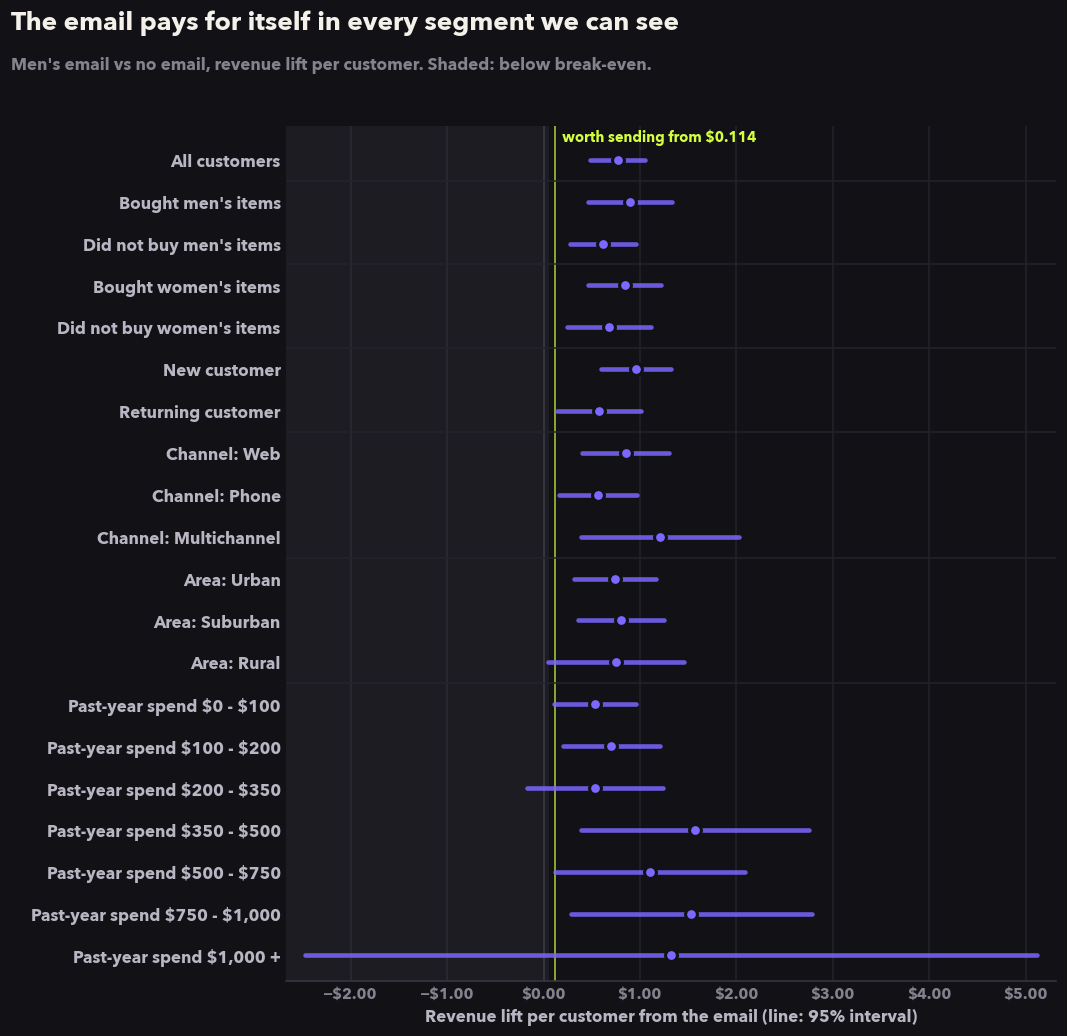

In [2]:
hist = sorted(d["history_segment"].unique())
segments = {
    "all": {"All customers": np.ones(len(d), bool)},
    "mens": {"Bought men's items": d["mens"] == 1, "Did not buy men's items": d["mens"] == 0},
    "womens": {"Bought women's items": d["womens"] == 1, "Did not buy women's items": d["womens"] == 0},
    "newbie": {"New customer": d["newbie"] == 1, "Returning customer": d["newbie"] == 0},
    "channel": {f"Channel: {c}": d["channel"] == c for c in ["Web", "Phone", "Multichannel"]},
    "area": {f"Area: {a.replace('Surburban', 'Suburban')}": d["zip_code"] == a
             for a in ["Urban", "Surburban", "Rural"]},
    "history": {f"Past-year spend {h.split(') ')[1]}": d["history_segment"] == h for h in hist},
}
seg = segment_effects(d, segments, "spend", "mens_email")
fig, ax = plots.segment_lift_plot(seg, "mens_email", econ.break_even_lift, econ.worthwhile_lift)
style.headline(fig, "The email pays for itself in every segment we can see",
               "Men's email vs no email, revenue lift per customer. Shaded: below break-even.")
style.save(fig, "segments")

In [3]:
def usd(v):
    return f"{'+' if v >= 0 else '-'}${abs(v):.2f}"

seg.assign(**{"Lift": seg["effect"].map(usd),
              "95% interval": [f"{usd(lo)} to {usd(hi)}" for lo, hi in zip(seg["ci_low"], seg["ci_high"])]}
           )[["label", "customers", "buyers", "Lift", "95% interval"]].rename(
    columns={"label": "Segment", "customers": "Customers", "buyers": "Buyers"}
).style.format({"Customers": "{:,}"}).hide(axis="index")

Segment,Customers,Buyers,Lift,95% interval
All customers,"42,613",389,+$0.77,+$0.49 to +$1.05
Bought men's items,"23,526",236,+$0.90,+$0.46 to +$1.33
Did not buy men's items,"19,087",153,+$0.62,+$0.27 to +$0.96
Bought women's items,"23,417",226,+$0.84,+$0.47 to +$1.22
Did not buy women's items,"19,196",163,+$0.68,+$0.25 to +$1.12
New customer,"21,381",159,+$0.96,+$0.59 to +$1.33
Returning customer,"21,232",230,+$0.58,+$0.14 to +$1.01
Channel: Web,"18,863",177,+$0.85,+$0.40 to +$1.30
Channel: Phone,"18,567",150,+$0.56,+$0.16 to +$0.97
Channel: Multichannel,"5,183",62,+$1.21,+$0.39 to +$2.03


Every point estimate sits far above the 5.7 cent break-even, the lowest at about 54 cents. Some segments look stronger (higher past spend, new customers, multichannel buyers), but their intervals are wide and overlap heavily. Many segments rest on a few dozen buyers, the same territory where notebook 03 found standard methods unreliable.

## 2. Two uplift models, judged on unseen customers

Both models use the same seven customer features. Every customer is scored by a model trained on the *other* half of the data (cross-fitting), so no model is graded on customers it learned from.

The yardstick is the **Qini curve**: rank customers by predicted uplift, email them in that order, and track the extra revenue gained. A model that has found who responds most rises faster than the straight line of random targeting.

For comparison there is also a **one-line rule** that needs no model at all: email customers with higher past-year spend first.

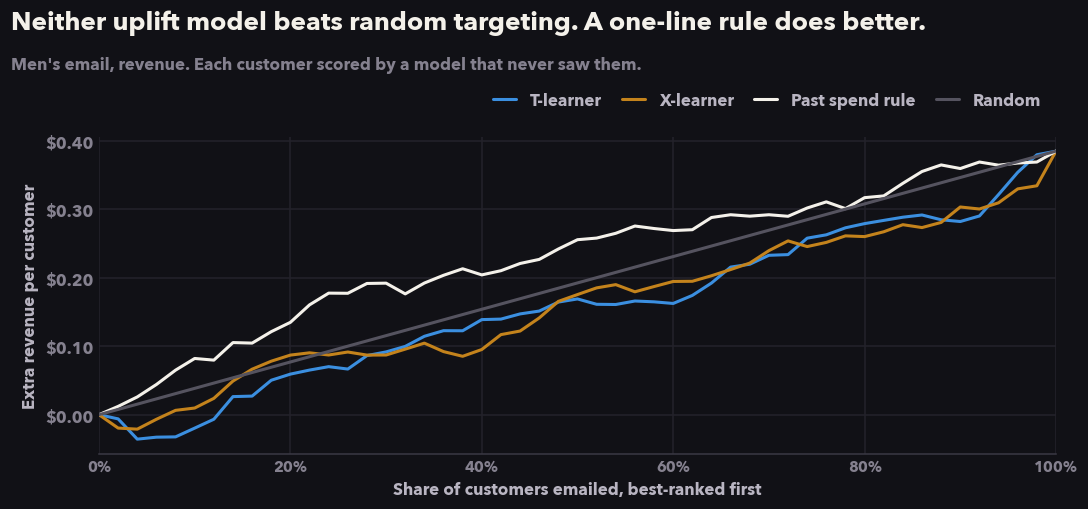

In [4]:
scores = {
    "T-learner": cross_fit_scores(TLearner, X, y, t, seed=0),
    "X-learner": cross_fit_scores(XLearner, X, y, t, seed=0),
    "Past spend rule": d["history"].to_numpy(),
}
curves = {name: qini_curve(s, y, t) for name, s in scores.items()}
curves["Random"] = curves["T-learner"]
fig, ax = plots.qini_plot(curves)
style.headline(fig, "Neither uplift model beats random targeting. A one-line rule does better.",
               "Men's email, revenue. Each customer scored by a model that never saw them.")
style.save(fig, "qini")

In [5]:
rows = []
for name, s in scores.items():
    boot = bootstrap_qini(s, y, t, n_boot=300, seed=1)
    rows.append({"Ranking": name, "Qini score": qini_coefficient(s, y, t),
                 "95% interval": f"{np.quantile(boot, 0.025):+.3f} to {np.quantile(boot, 0.975):+.3f}"})
pd.DataFrame(rows).style.format({"Qini score": "{:+.3f}"}).hide(axis="index")

Ranking,Qini score,95% interval
T-learner,-0.034,-0.076 to +0.008
X-learner,-0.031,-0.074 to +0.014
Past spend rule,+0.038,-0.002 to +0.080


## 3. Is it stable? Re-split the data 20 times

One split can be lucky or unlucky. So the data is halved at random 20 times; each time the models are trained on one half and scored on the other. The past spend rule needs no training, so it is simply scored on the same held-out halves.

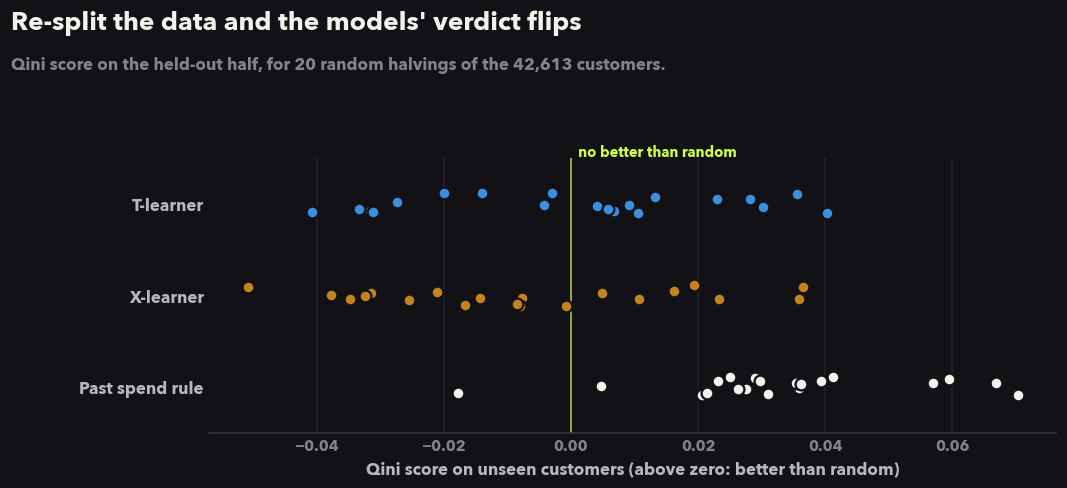

In [6]:
def model_scores(Learner):
    return lambda Xtr, ytr, ttr, Xte, idx: Learner().fit(Xtr, ytr, ttr).predict(Xte)

history = d["history"].to_numpy()
stability = {
    "T-learner": split_qini(model_scores(TLearner), X, y, t, n_splits=20, seed=2),
    "X-learner": split_qini(model_scores(XLearner), X, y, t, n_splits=20, seed=2),
    "Past spend rule": split_qini(lambda Xtr, ytr, ttr, Xte, idx: history[idx], X, y, t, n_splits=20, seed=2),
}
fig, ax = plots.stability_plot(stability)
style.headline(fig, "Re-split the data and the models' verdict flips",
               "Qini score on the held-out half, for 20 random halvings of the 42,613 customers.")
style.save(fig, "qini_stability")

In [7]:
pd.DataFrame({name: {"Better than random": f"{(v > 0).mean():.0%} of splits",
                     "Average Qini": f"{v.mean():+.3f}"} for name, v in stability.items()}).T

,Better than random,Average Qini
T-learner,55% of splits,+0.000
X-learner,35% of splits,-0.007
Past spend rule,95% of splits,+0.033


## What this tells us

- **The email works for everyone we can tell apart.** Every segment's lift is roughly ten times the break-even, so there is no obvious group to leave out.
- **Two standard uplift models found nothing they could repeat.** On customers they never saw, both ranked people no better than random, and their verdict flipped from split to split. With about 390 buyers between the two groups, there is not enough signal in revenue to learn *who* responds more, and a flexible model fits the noise instead.
- **A one-line rule did better than both models.** Emailing higher spenders first beat random in 19 of the 20 splits. Its interval on the full data still touches zero, so it is a hint rather than proof, but it is a reminder that a model's real baseline is the simplest sensible rule, not random.
- **The question for the business is not "which model?" but "is targeting worth it at all?"** Notebook 09 answers that in dollars.